In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
raw_data = pd.read_csv("data/dataset.csv", sep=";", decimal=",", encoding="latin-1")
data = raw_data.copy()
data.head(5)

,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,Fire,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%)
0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4.1
1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,6.6
2,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8.7
3,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.2
4,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,11.1


In [68]:
# Tratemento dos dados
incidentes_cols = [col for col in data.columns if col not in ["Slowness in traffic (%)", "Hour (Coded)"]]
data["day_coded"] = np.arange(len(data)) / 28
data['day_coded'] = data['day_coded'].astype(int)
data['Hour (Coded)'] = data['Hour (Coded)'].astype(int)
data['has_incident'] = (data[incidentes_cols].sum(axis=1) > 0).astype(int)
data['incident_total'] = data[incidentes_cols].sum(axis=1)
data.head()

['Immobilized bus', 'Broken Truck', 'Vehicle excess', 'Accident victim', 'Running over', 'Fire vehicles', 'Occurrence involving freight', 'Incident involving dangerous freight', 'Lack of electricity', 'Fire', 'Point of flooding', 'Manifestations', 'Defect in the network of trolleybuses', 'Tree on the road', 'Semaphore off', 'Intermittent Semaphore']


,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,...,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%),day_coded,has_incident,incident_total
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,4.1,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,6.6,0,0,0
2,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,8.7,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,9.2,0,0,0
4,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,11.1,0,0,0


In [25]:
# Analíse Exploratória
print(f"Ausentes:\n{data.isna().sum()}")
print(f"\nDimensões: {data.shape}\n")
slowness_describe = data['Slowness in traffic (%)'].describe()
slowness_describe["variance"] = data['Slowness in traffic (%)'].var()
slowness_describe["iqr"] = data['Slowness in traffic (%)'].quantile(0.75) - data['Slowness in traffic (%)'].quantile(0.25)
print(slowness_describe)


Ausentes:
Hour (Coded)                             0
Immobilized bus                          0
Broken Truck                             0
Vehicle excess                           0
Accident victim                          0
Running over                             0
Fire vehicles                            0
Occurrence involving freight             0
Incident involving dangerous freight     0
Lack of electricity                      0
Fire                                     0
Point of flooding                        0
Manifestations                           0
Defect in the network of trolleybuses    0
Tree on the road                         0
Semaphore off                            0
Intermittent Semaphore                   0
Slowness in traffic (%)                  0
day_coded                                0
has_incident                             0
incident_total                           0
dtype: int64

Dimensões: (135, 21)

count       135.000000
mean         10.051852
std  

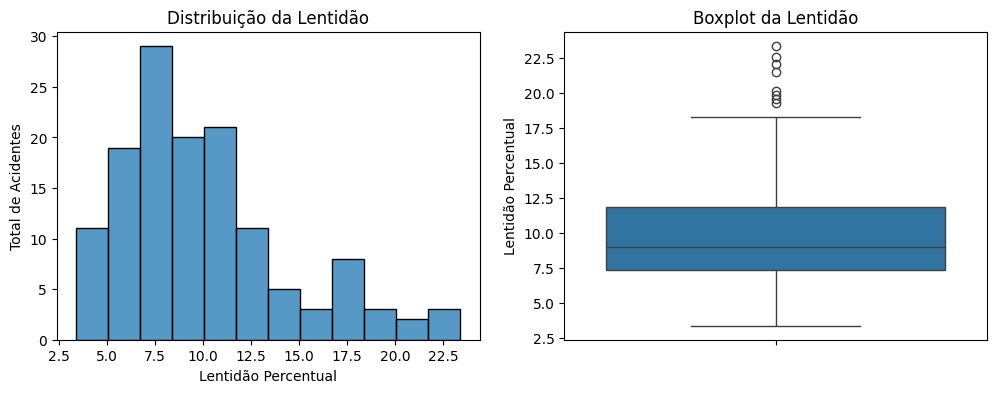

In [54]:
fig, axs = plt.subplots(1,2, figsize=(12,4))

sns.histplot(
    data=data,
    x='Slowness in traffic (%)',
    ax=axs[0]
)

sns.boxplot(
    data=data,
    y='Slowness in traffic (%)',
    ax=axs[1]
)

axs[0].set_title("Distribuição da Lentidão")
axs[0].set_xlabel("Lentidão Percentual")
axs[0].set_ylabel("Total de Acidentes")
axs[1].set_title("Boxplot da Lentidão")
axs[1].set_ylabel("Lentidão Percentual")
plt.show()

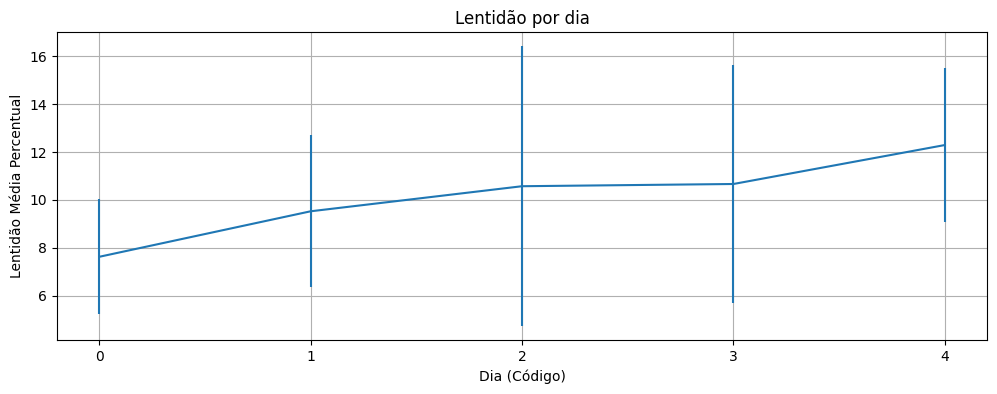

In [55]:
slow = "Slowness in traffic (%)"
plt.figure(figsize=(12,4))
slow_por_dia = data.groupby('day_coded')[slow].agg(["count", "mean", "std"])
plt.errorbar(
    x=slow_por_dia.index,
    y=slow_por_dia['mean'],
    yerr=slow_por_dia['std']
)
plt.xticks(slow_por_dia.index)
plt.title("Lentidão por dia")
plt.xlabel("Dia (Código)")
plt.ylabel("Lentidão Média Percentual")
plt.grid(True)
plt.show()

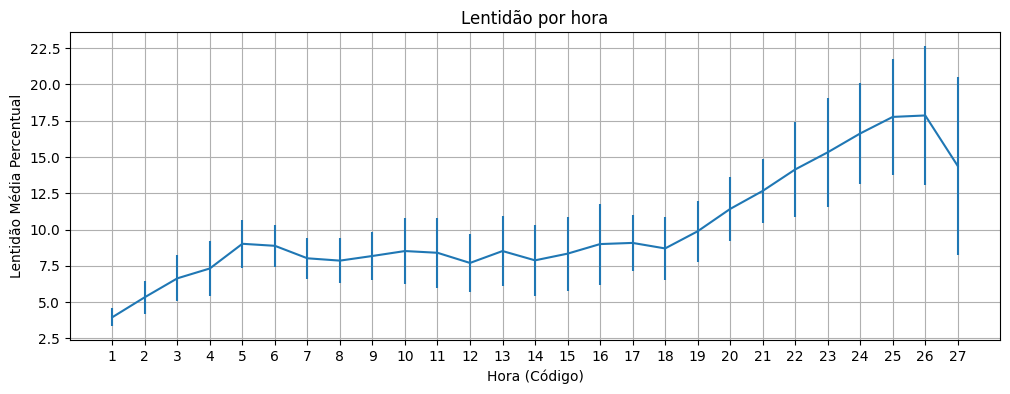

In [56]:
hour = "Hour (Coded)"
plt.figure(figsize=(12,4))
slow_por_hora = data.groupby(hour)[slow].agg(["count", "mean", "std"])
plt.errorbar(
    x=slow_por_hora.index,
    y=slow_por_hora['mean'],
    yerr=slow_por_hora['std']
)
plt.xticks(slow_por_hora.index)
plt.title("Lentidão por hora")
plt.xlabel("Hora (Código)")
plt.ylabel("Lentidão Média Percentual")
plt.grid(True)
plt.show()

              count       mean
has_incident                  
0                35   8.871429
1               100  10.465000


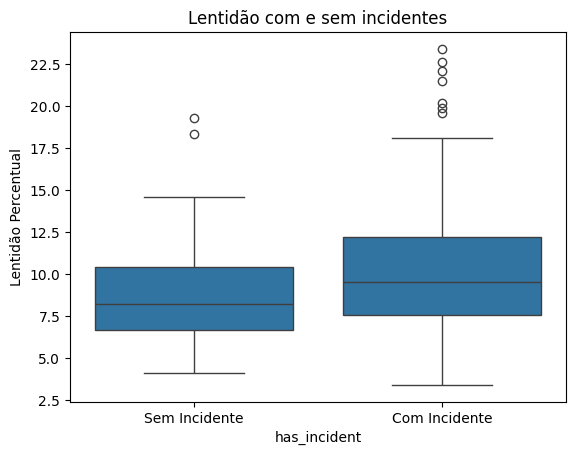

In [69]:
sns.boxplot(
    data=data,
    x="has_incident",
    y=slow
)
print(data.groupby("has_incident")[slow].agg(["count", "mean"]))
plt.xticks([0,1],["Sem Incidente", "Com Incidente"])
plt.title("Lentidão com e sem incidentes")
plt.ylabel("Lentidão Percentual")
plt.show()

In [ ]:
sns.lineplot(

)